# Global Solution de MLAM — Demanda por bicicletas compartilhadas

Como parte do desafio CitizenTech, investigamos como a temperatura e a umidade se relacionam com o número diário de aluguéis de bicicletas. Para isso, usamos dados reais de 731 dias do sistema Capital Bikeshare, entre 2011 e 2012. Entender essa relação pode ajudar no planejamento da oferta de bicicletas.

**Fonte dos dados:** [Bike Sharing Dataset — Kaggle](https://www.kaggle.com/datasets/lakshmi25npathi/bike-sharing-dataset)

## 01) Escolha da base de dados

Escolhemos o arquivo `day.csv` porque cada linha reúne, para um mesmo dia, o total de aluguéis de bicicletas (`cnt`), a temperatura (`temp`) e a umidade (`hum`). Isso permite investigar a relação entre as condições do tempo e a procura por bicicletas compartilhadas.

In [1]:
import pandas as pd

dados = pd.read_csv("day.csv")

print("Quantidade de dias:", len(dados))
dados[["dteday", "temp", "hum", "cnt"]].head()

Quantidade de dias: 731


,dteday,temp,hum,cnt
0,2011-01-01,0.344167,0.805833,985
1,2011-01-02,0.363478,0.696087,801
2,2011-01-03,0.196364,0.437273,1349
3,2011-01-04,0.200000,0.590435,1562
4,2011-01-05,0.226957,0.436957,1600


## 02) Distribuição Normal de Probabilidade

A variável escolhida é `cnt`, que representa o número de aluguéis de bicicletas em um dia. Conforme a hipótese do enunciado, vamos usar uma distribuição normal para calcular as probabilidades.

In [2]:
from scipy.stats import norm

alugueis = dados["cnt"]

media = alugueis.mean()
mediana = alugueis.median()
desvio_pop = alugueis.std(ddof=0)

print(f"Média: {media:.2f} aluguéis")
print(f"Mediana: {mediana:.0f} aluguéis")
print(f"Desvio padrão populacional: {desvio_pop:.2f} aluguéis")

Média: 4504.35 aluguéis
Mediana: 4548 aluguéis
Desvio padrão populacional: 1935.89 aluguéis


### A) Probabilidade de o número de aluguéis ser menor que a média

In [3]:
prob_a = norm.cdf(media, loc=media, scale=desvio_pop)

print(f"Probabilidade de ficar abaixo da média: {prob_a:.2%}")

Probabilidade de ficar abaixo da média: 50.00%


A probabilidade é de 50%. Como a distribuição normal é simétrica em torno da média, ficar abaixo dela e ficar acima dela são eventos igualmente prováveis.

### B) Probabilidade de o número de aluguéis ser maior que a mediana

In [4]:
prob_b = norm.sf(mediana, loc=media, scale=desvio_pop)

print(f"Probabilidade de superar a mediana: {prob_b:.2%}")

Probabilidade de superar a mediana: 49.10%


Pelo modelo normal, a probabilidade de superar a mediana observada de 4.548 aluguéis é de aproximadamente 49,10%. O evento é ligeiramente menos provável que seu complemento, pois a mediana observada está um pouco acima da média usada no modelo.

## 03) Testes de hipóteses para a média

Usaremos a média dos 731 dias como referência. Em cada teste, vamos sortear uma amostra de dias e verificar se há evidência de que a média é menor ou maior que a referência. Como o enunciado fornece o desvio padrão populacional a partir da base, aplicaremos o teste Z unilateral.

### A) Teste para uma média menor que a referência

- H₀: a média é igual à média de referência.
- H₁: a média é menor que a média de referência.
- Tamanho da amostra: 20 dias.
- Nível de significância: 6%.

In [5]:
amostra_a = alugueis.sample(n=20, random_state=42)
media_a = amostra_a.mean()

erro_padrao_a = desvio_pop / (20 ** 0.5)
z_a = (media_a - media) / erro_padrao_a
p_valor_a = norm.cdf(z_a)

print(f"Média de referência: {media:.2f}")
print(f"Média da amostra: {media_a:.2f}")
print(f"Estatística Z: {z_a:.3f}")
print(f"Valor-p: {p_valor_a:.4f}")

if p_valor_a <= 0.06:
    print("Rejeitamos H₀. Há evidência de que a média é menor que a referência.")
else:
    print("Não rejeitamos H₀. A amostra não fornece evidência suficiente de uma média menor.")

Média de referência: 4504.35
Média da amostra: 4364.15
Estatística Z: -0.324
Valor-p: 0.3730
Não rejeitamos H₀. A amostra não fornece evidência suficiente de uma média menor.


Nos 20 dias sorteados, a média foi de 4.364,15 aluguéis por dia, abaixo da referência de 4.504,35. Como o valor-p (0,3730) foi maior que o nível de significância (0,06), não rejeitamos H₀. A amostra não fornece evidência suficiente para concluir que a média diária de aluguéis seja menor que a referência.

### B) Teste para uma média maior que a referência

- H₀: a média é igual à média de referência.
- H₁: a média é maior que a média de referência.
- Tamanho da amostra: 25 dias.
- Nível de significância: 9%.

In [6]:
amostra_b = alugueis.sample(n=25, random_state=43)
media_b = amostra_b.mean()

erro_padrao_b = desvio_pop / (25 ** 0.5)
z_b = (media_b - media) / erro_padrao_b
p_valor_b = norm.sf(z_b)

print(f"Média de referência: {media:.2f}")
print(f"Média da amostra: {media_b:.2f}")
print(f"Estatística Z: {z_b:.3f}")
print(f"Valor-p: {p_valor_b:.4f}")

if p_valor_b <= 0.09:
    print("Rejeitamos H₀. Há evidência de que a média é maior que a referência.")
else:
    print("Não rejeitamos H₀. A amostra não fornece evidência suficiente de uma média maior.")

Média de referência: 4504.35
Média da amostra: 4769.56
Estatística Z: 0.685
Valor-p: 0.2467
Não rejeitamos H₀. A amostra não fornece evidência suficiente de uma média maior.


Nos 25 dias sorteados, a média foi de 4.769,56 aluguéis por dia, acima da referência de 4.504,35. Como o valor-p (0,2467) foi maior que o nível de significância (0,09), não rejeitamos H₀. A amostra não fornece evidência suficiente para concluir que a média diária de aluguéis seja maior que a referência.

## 04) Análise bivariada

### A) Gráfico de dispersão entre temperatura e aluguéis

Cada ponto representa um dia. No eixo horizontal, temos a temperatura normalizada (`temp`). No eixo vertical, temos o total de aluguéis de bicicletas naquele dia (`cnt`).

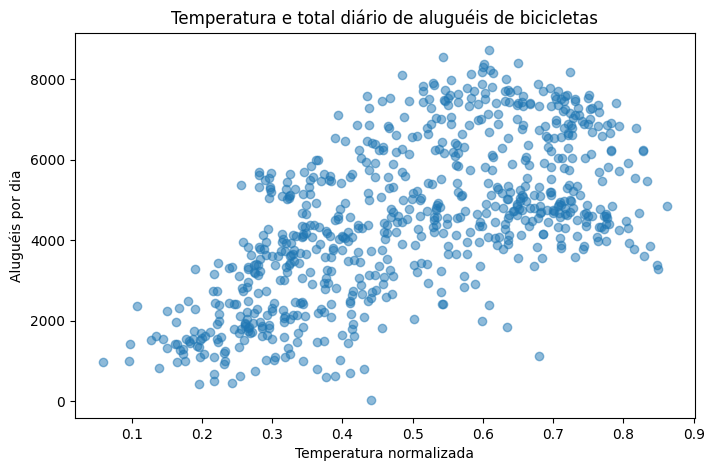

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(dados["temp"], dados["cnt"], alpha=0.5)
plt.title("Temperatura e total diário de aluguéis de bicicletas")
plt.xlabel("Temperatura normalizada")
plt.ylabel("Aluguéis por dia")
plt.show()

O gráfico mostra uma associação positiva entre a temperatura e o total diário de aluguéis. Em geral, os dias mais quentes registraram mais aluguéis. Ainda assim, em dias com temperatura normalizada próxima de 0,6, observamos tanto valores em torno de 4.000 quanto valores próximos de 8.000 aluguéis. Essa variação indica que a temperatura, sozinha, explica apenas parte das diferenças entre os dias.

### B) Covariância e correlação linear de Pearson

Calculamos a covariância e a correlação de Pearson entre a temperatura normalizada (`temp`) e o total diário de aluguéis (`cnt`).

In [8]:
covariancia = dados["temp"].cov(dados["cnt"])
correlacao = dados["temp"].corr(dados["cnt"], method="pearson")

print(f"Covariância: {covariancia:.2f}")
print(f"Correlação de Pearson: {correlacao:.4f}")

Covariância: 222.51
Correlação de Pearson: 0.6275


A covariância de 222,51 é positiva, indicando que temperaturas mais altas estiveram associadas a um maior número de aluguéis. A correlação de Pearson de 0,6275 indica uma associação linear positiva de intensidade moderada. Esse resultado é coerente com o gráfico de dispersão, em que a tendência é crescente, mas dias com temperaturas semelhantes podem apresentar totais de aluguéis diferentes.

### C) Gráfico de correlação linear de Pearson

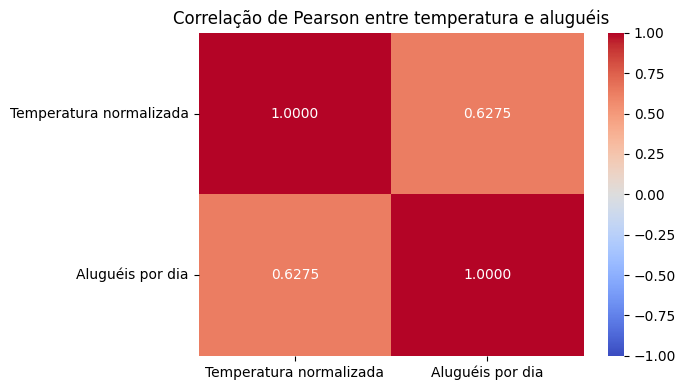

In [9]:
import seaborn as sns

variaveis = dados[["temp", "cnt"]].rename(columns={
    "temp": "Temperatura normalizada",
    "cnt": "Aluguéis por dia"
})

matriz_correlacao = variaveis.corr(method="pearson")

plt.figure(figsize=(7, 4))
sns.heatmap(
    matriz_correlacao,
    annot=True,
    fmt=".4f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)
plt.title("Correlação de Pearson entre temperatura e aluguéis")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Na diagonal, o valor 1,0000 aparece porque cada variável tem correlação perfeita consigo mesma. Fora da diagonal, o valor 0,6275 aparece duas vezes porque a correlação entre temperatura e aluguéis é a mesma em qualquer ordem. Esse é o valor que representa a associação positiva entre as duas variáveis.

### D) Reta e equação da regressão linear simples

Ajustamos uma regressão linear simples usando a temperatura normalizada como variável explicativa (X) e o total diário de aluguéis como variável resposta (y). A reta mostra o número médio de aluguéis estimado pelo modelo para cada temperatura.

Equação: aluguéis estimados = 1214.64 + 6640.71 × temp
Aumento estimado para +0,10 em temp: 664 aluguéis por dia


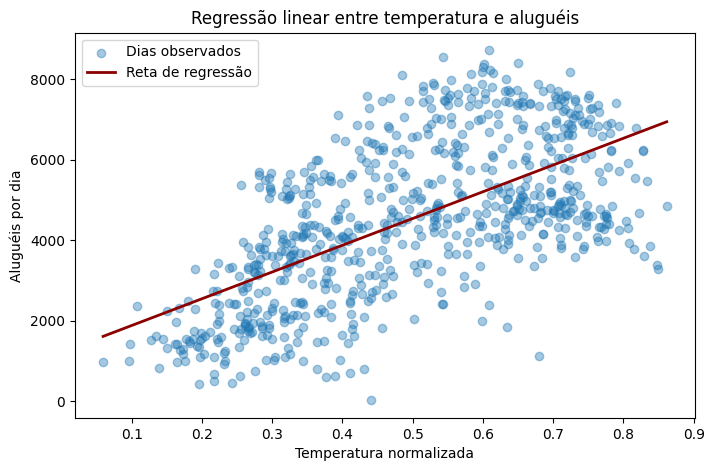

In [10]:
from sklearn.linear_model import LinearRegression

X_simples = dados[["temp"]]
y = dados["cnt"]

modelo_simples = LinearRegression()
modelo_simples.fit(X_simples, y)

intercepto = modelo_simples.intercept_
inclinacao = modelo_simples.coef_[0]

print(f"Equação: aluguéis estimados = {intercepto:.2f} + {inclinacao:.2f} × temp")
print(f"Aumento estimado para +0,10 em temp: {0.10 * inclinacao:.0f} aluguéis por dia")

# Desenhar a reta entre a menor e a maior temperatura observada
temperaturas_reta = pd.DataFrame({
    "temp": [dados["temp"].min(), dados["temp"].max()]
})
alugueis_reta = modelo_simples.predict(temperaturas_reta)

plt.figure(figsize=(8, 5))
plt.scatter(dados["temp"], y, alpha=0.4, label="Dias observados")
plt.plot(temperaturas_reta["temp"], alugueis_reta,
         color="darkred", linewidth=2, label="Reta de regressão")
plt.title("Regressão linear entre temperatura e aluguéis")
plt.xlabel("Temperatura normalizada")
plt.ylabel("Aluguéis por dia")
plt.legend()
plt.show()

A equação ajustada foi: aluguéis estimados = 1.214,64 + 6.640,71 × temperatura normalizada. Quando a temperatura normalizada passa de 0,50 para 0,60, por exemplo, o modelo estima cerca de 664 aluguéis a mais por dia. A reta resume essa tendência média, enquanto a dispersão dos pontos mostra que dias com temperaturas semelhantes tiveram totais de aluguéis diferentes.

### E) Verificação da adequação do modelo: R² e teste F

Calculamos o R² da regressão e aplicamos o teste F para avaliar a contribuição da temperatura para o modelo. Adotamos o nível de significância de 5%.

- H₀: o coeficiente da temperatura é igual a zero.
- H₁: o coeficiente da temperatura é diferente de zero.

In [11]:
from sklearn.feature_selection import f_regression

r2_simples = modelo_simples.score(X_simples, y)
valores_f, valores_p = f_regression(X_simples, y)

print(f"R²: {r2_simples:.4f}")
print(f"Variação explicada pelo modelo: {r2_simples:.2%}")
print(f"Estatística F: {valores_f[0]:.2f}")
print(f"Valor-p do teste F: {valores_p[0]:.3e}")

R²: 0.3937
Variação explicada pelo modelo: 39.37%
Estatística F: 473.47
Valor-p do teste F: 2.811e-81


O R² de 0,3937 indica que a temperatura explica 39,37% da variação no total diário de aluguéis nos 731 dias analisados. No teste F, obtivemos F = 473,47 e valor-p de 2,811 × 10⁻⁸¹. Como o valor-p é menor que 0,05, rejeitamos H₀. Incluir a temperatura melhora significativamente o ajuste em relação a usar apenas a média de aluguéis. Ainda assim, 60,63% da variação permanece sem explicação por esse modelo.

### F) Previsão do total diário de aluguéis

Usamos a regressão linear simples para estimar o total de aluguéis em um dia com temperatura normalizada de 0,60.

In [12]:
novo_dia = pd.DataFrame({"temp": [0.60]})
previsao_simples = modelo_simples.predict(novo_dia)[0]

print(f"Total estimado: {previsao_simples:.0f} aluguéis no dia")

Total estimado: 5199 aluguéis no dia


Para um dia com temperatura normalizada de 0,60, o modelo estima aproximadamente 5.199 aluguéis. Esse valor corresponde à altura da reta nessa temperatura. No gráfico, os pontos próximos de 0,60 aparecem tanto acima quanto abaixo da reta, mostrando como o total observado pode variar em torno da previsão.

## 05) Regressão linear múltipla

Neste item, vamos analisar a relação da temperatura e da umidade com o total diário de aluguéis de bicicletas.

### A) Gráfico de dispersão entre temperatura, umidade e aluguéis

Cada ponto representa um dia. A posição indica a temperatura normalizada e o número de aluguéis, enquanto a cor representa a umidade relativa do ar.

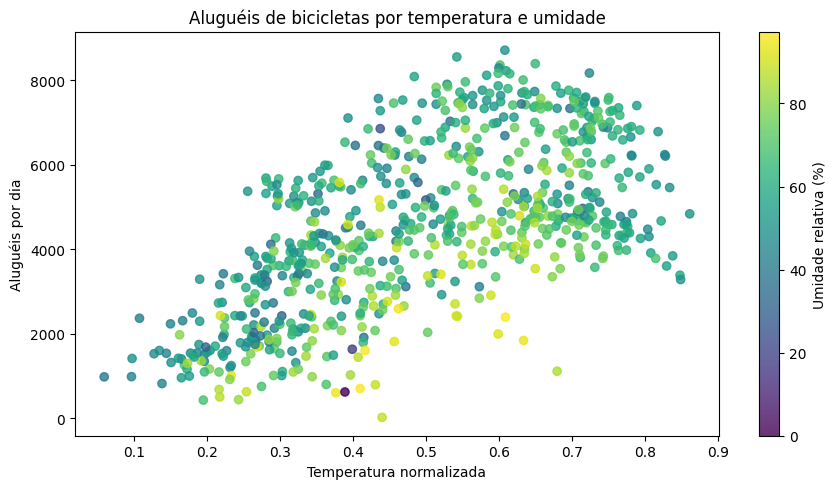

In [13]:
plt.figure(figsize=(9, 5))

pontos = plt.scatter(
    dados["temp"],
    dados["cnt"],
    c=dados["hum"] * 100,
    cmap="viridis",
    alpha=0.8
)

plt.colorbar(pontos, label="Umidade relativa (%)")
plt.xlabel("Temperatura normalizada")
plt.ylabel("Aluguéis por dia")
plt.title("Aluguéis de bicicletas por temperatura e umidade")
plt.tight_layout()
plt.show()

O total de aluguéis tende a aumentar com a temperatura. Na faixa de temperatura normalizada entre 0,5 e 0,7, vários dos pontos amarelos, que representam os dias de maior umidade, aparecem entre os menores totais de aluguéis. Há também dias úmidos com totais mais altos. Assim, o gráfico sugere que a umidade pode ajudar a entender parte da variação entre dias com temperaturas semelhantes.

### B) Matrizes de covariância e de correlação de Pearson

Calculamos as duas matrizes para examinar as relações entre temperatura, umidade e total diário de aluguéis. O sinal da covariância indica a direção de cada associação. A correlação de Pearson permite comparar a intensidade das associações lineares em uma escala de −1 a +1.

In [14]:
variaveis_05 = dados[["temp", "hum", "cnt"]].rename(columns={
    "temp": "Temperatura",
    "hum": "Umidade",
    "cnt": "Aluguéis"
})

matriz_cov_05 = variaveis_05.cov()
matriz_corr_05 = variaveis_05.corr(method="pearson")

print("Matriz de covariância")
display(matriz_cov_05.round(4))

print("Matriz de correlação de Pearson")
display(matriz_corr_05.round(4))

Matriz de covariância


,Temperatura,Umidade,Aluguéis
Temperatura,0.0335,0.0033,2.225147e+02
Umidade,0.0033,0.0203,-2.777320e+01
Aluguéis,222.5147,-27.7732,3.752788e+06


Matriz de correlação de Pearson


,Temperatura,Umidade,Aluguéis
Temperatura,1.0000,0.1270,0.6275
Umidade,0.1270,1.0000,-0.1007
Aluguéis,0.6275,-0.1007,1.0000


A temperatura apresentou covariância positiva com os aluguéis (222,5147) e correlação de Pearson de 0,6275, indicando uma associação linear positiva moderada. Dias mais quentes tenderam a registrar mais aluguéis.

A umidade apresentou covariância negativa com os aluguéis (−27,7732) e correlação de −0,1007. Assim, considerando todos os dias, a associação linear entre umidade e aluguéis foi negativa e fraca.

Entre temperatura e umidade, a covariância foi de 0,0033 e a correlação foi de 0,1270, indicando uma associação linear positiva fraca.

### C) Gráfico de correlação linear de Pearson

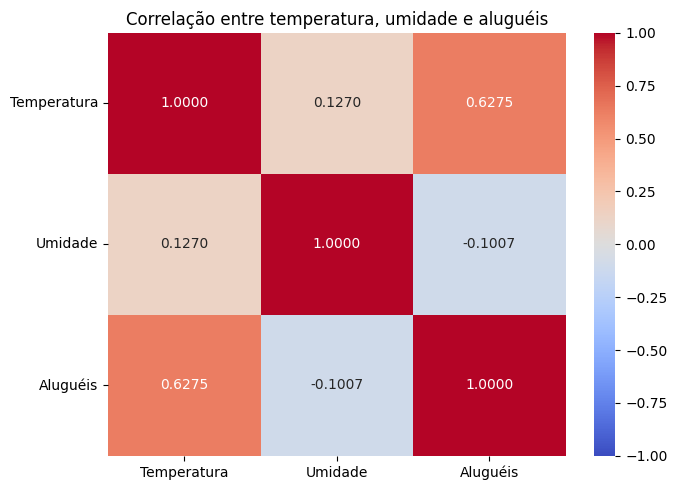

In [15]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz_corr_05,
    annot=True,
    fmt=".4f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlação entre temperatura, umidade e aluguéis")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Fora da diagonal, o par temperatura–aluguéis se destaca no mapa de calor (0,6275). Os dois pares que envolvem a umidade apresentam cores próximas ao centro da escala, pois suas correlações estão próximas de zero. Entre as duas variáveis climáticas analisadas individualmente, a temperatura tem a associação linear mais forte com o total diário de aluguéis.

### D) Equação da regressão linear múltipla

Ajustamos um modelo para estimar o total diário de aluguéis (`cnt`) a partir da temperatura (`temp`) e da umidade (`hum`). Cada coeficiente indica quanto a estimativa varia quando alteramos uma das variáveis e mantemos a outra constante.

In [16]:
X_multipla = dados[["temp", "hum"]]
y = dados["cnt"]

modelo_multiplo = LinearRegression()
modelo_multiplo.fit(X_multipla, y)

intercepto = modelo_multiplo.intercept_
coef_temp, coef_hum = modelo_multiplo.coef_

print(
    f"Aluguéis estimados = {intercepto:.2f} "
    f"{coef_temp:+.2f} × temp {coef_hum:+.2f} × hum"
)

print(f"Temperatura de 0,50 para 0,60, com umidade fixa: {0.10 * coef_temp:+.0f} aluguéis/dia")
print(f"Umidade de 60% para 70%, com temperatura fixa: {0.10 * coef_hum:+.0f} aluguéis/dia")

Aluguéis estimados = 2657.90 +6886.97 × temp -2492.85 × hum
Temperatura de 0,50 para 0,60, com umidade fixa: +689 aluguéis/dia
Umidade de 60% para 70%, com temperatura fixa: -249 aluguéis/dia


A equação ajustada foi: aluguéis estimados = 2.657,90 + 6.886,97 × temp − 2.492,85 × hum.

Mantendo a umidade fixa, o modelo estima cerca de 689 aluguéis a mais por dia quando a temperatura normalizada passa de 0,50 para 0,60. Mantendo a temperatura fixa, o modelo estima cerca de 249 aluguéis a menos por dia quando a umidade passa de 60% para 70%.

### E) Verificação da adequação do modelo: R² e teste F global

Comparamos o R² da regressão múltipla com o da regressão simples e adotamos um nível de significância de 5% para o teste F global.

- H₀: os coeficientes da temperatura e da umidade são ambos iguais a zero.
- H₁: pelo menos um desses coeficientes é diferente de zero.

In [17]:
import statsmodels.api as sm

# A constante representa o intercepto, como no modelo da letra D.
X_com_constante = sm.add_constant(X_multipla)
ajuste_multiplo = sm.OLS(y, X_com_constante).fit()

r2_multiplo = ajuste_multiplo.rsquared
ganho_pp = (r2_multiplo - r2_simples) * 100

print(f"R² do modelo simples: {r2_simples:.2%}")
print(f"R² do modelo múltiplo: {r2_multiplo:.2%}")
print(f"Ganho com a inclusão da umidade: {ganho_pp:.2f} pontos percentuais")
print(f"Estatística F global: {ajuste_multiplo.fvalue:.2f}")
print(f"Valor-p do teste F global: {ajuste_multiplo.f_pvalue:.3e}")

R² do modelo simples: 39.37%
R² do modelo múltiplo: 42.68%
Ganho com a inclusão da umidade: 3.31 pontos percentuais
Estatística F global: 271.03
Valor-p do teste F global: 1.056e-88


Nos 731 dias analisados, o modelo com temperatura e umidade explicou 42,68% da variação no total diário de aluguéis. O modelo que usava apenas a temperatura explicava 39,37%. Assim, incluir a umidade aumentou a parcela explicada em 3,31 pontos percentuais.

O teste F global apresentou F = 271,03 e valor-p de 1,056 × 10⁻⁸⁸. Como o valor-p é menor que 0,05, rejeitamos H₀. Há evidência de que pelo menos uma das duas variáveis contribui para explicar a variação nos aluguéis.

### F) Previsão do total diário de aluguéis

Usamos o modelo de regressão linear múltipla para estimar a demanda em um dia com temperatura normalizada de 0,60 e umidade relativa de 70%.

In [18]:
novo_dia_multiplo = pd.DataFrame({
    "temp": [0.60],
    "hum": [0.70]
})

previsao_multipla = modelo_multiplo.predict(novo_dia_multiplo)[0]
print(f"Total estimado: {previsao_multipla:.0f} aluguéis no dia")

Total estimado: 5045 aluguéis no dia


Para um dia com temperatura normalizada de 0,60 e umidade relativa de 70%, o modelo múltiplo estima aproximadamente 5.045 aluguéis. Para a mesma temperatura, o modelo simples estimava 5.199. Nesse cenário, a previsão do modelo que também considera a umidade é cerca de 154 aluguéis menor.

## 06) Regressão logística binária

### A) Equação da regressão logística

Usamos a temperatura normalizada (`temp`) e a umidade (`hum`) para estimar a probabilidade de alta demanda. A classe 1 representa os dias com total de aluguéis acima da mediana do treino. A classe 0 representa os dias com total igual ou inferior a essa mediana.

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

treino, teste = train_test_split(dados, test_size=0.30, random_state=42)

limite_demanda = treino["cnt"].median()

X_treino = treino[["temp", "hum"]]
X_teste = teste[["temp", "hum"]]

y_treino = (treino["cnt"] > limite_demanda).astype(int)
y_teste = (teste["cnt"] > limite_demanda).astype(int)

modelo_logistico = LogisticRegression()
modelo_logistico.fit(X_treino, y_treino)

b0 = modelo_logistico.intercept_[0]
b_temp, b_hum = modelo_logistico.coef_[0]

print(f"Dias de treino: {len(treino)} | Dias de teste: {len(teste)}")
print(f"Mediana do treino: {limite_demanda:.0f} aluguéis")
print(f"z = {b0:.4f} {b_temp:+.4f} × temp {b_hum:+.4f} × hum")
print("P(alta demanda) = 1 / (1 + exp(-z))")

Dias de treino: 511 | Dias de teste: 220
Mediana do treino: 4586 aluguéis
z = -1.4583 +5.4460 × temp -2.0157 × hum
P(alta demanda) = 1 / (1 + exp(-z))


A equação ajustada foi z = −1,4583 + 5,4460 × temp − 2,0157 × hum. A probabilidade estimada de alta demanda é P(alta demanda) = 1 / (1 + exp(−z)).

Mantendo a umidade fixa, temperaturas mais altas aumentam a probabilidade estimada de superar 4.586 aluguéis no dia. Mantendo a temperatura fixa, umidades mais altas reduzem essa probabilidade.

### B) Matriz de confusão e acurácia

Avaliamos o modelo nos 220 dias reservados para teste. Na matriz de confusão, as linhas representam a demanda observada e as colunas representam a demanda prevista. Os valores na diagonal indicam os acertos.

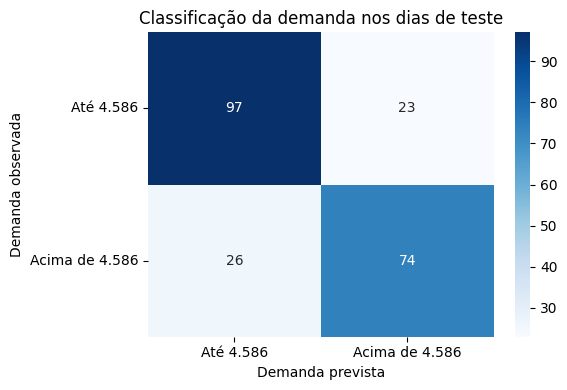

Dias classificados corretamente: 171 de 220
Acurácia: 77.73%


In [20]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_previsto = modelo_logistico.predict(X_teste)

matriz = confusion_matrix(y_teste, y_previsto, labels=[0, 1])
acuracia = accuracy_score(y_teste, y_previsto)

classes = ["Até 4.586", "Acima de 4.586"]

plt.figure(figsize=(6, 4))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)
plt.xlabel("Demanda prevista")
plt.ylabel("Demanda observada")
plt.title("Classificação da demanda nos dias de teste")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"Dias classificados corretamente: {matriz.trace()} de {len(y_teste)}")
print(f"Acurácia: {acuracia:.2%}")

O modelo classificou corretamente 171 dos 220 dias de teste, alcançando acurácia de 77,73%. Entre os 100 dias em que a demanda superou 4.586 aluguéis, o modelo identificou 74 e deixou de identificar 26. Entre os 120 dias com até 4.586 aluguéis, acertou 97 e sinalizou alta demanda em 23 por engano.

### C) Classificação de um dia com base na temperatura e na umidade

Aplicamos o modelo a um dia com temperatura normalizada de 0,60 e umidade relativa de 70% para verificar se ele seria classificado como um dia de alta demanda.

In [21]:
# Mesmo cenário usado na previsão da 05 F
prob_alta = modelo_logistico.predict_proba(novo_dia_multiplo)[0, 1]
classe_prevista = modelo_logistico.predict(novo_dia_multiplo)[0]

print(f"Probabilidade estimada de alta demanda: {prob_alta:.2%}")
print(f"Classe prevista: {classe_prevista}")

Probabilidade estimada de alta demanda: 59.83%
Classe prevista: 1


Para um dia com temperatura normalizada de 0,60 e umidade relativa de 70%, o modelo estimou uma probabilidade de 59,83% de superar 4.586 aluguéis. Como o valor ficou acima do limiar de 50%, o dia foi classificado como de alta demanda (classe 1).